# EDA

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


Distribution of the data

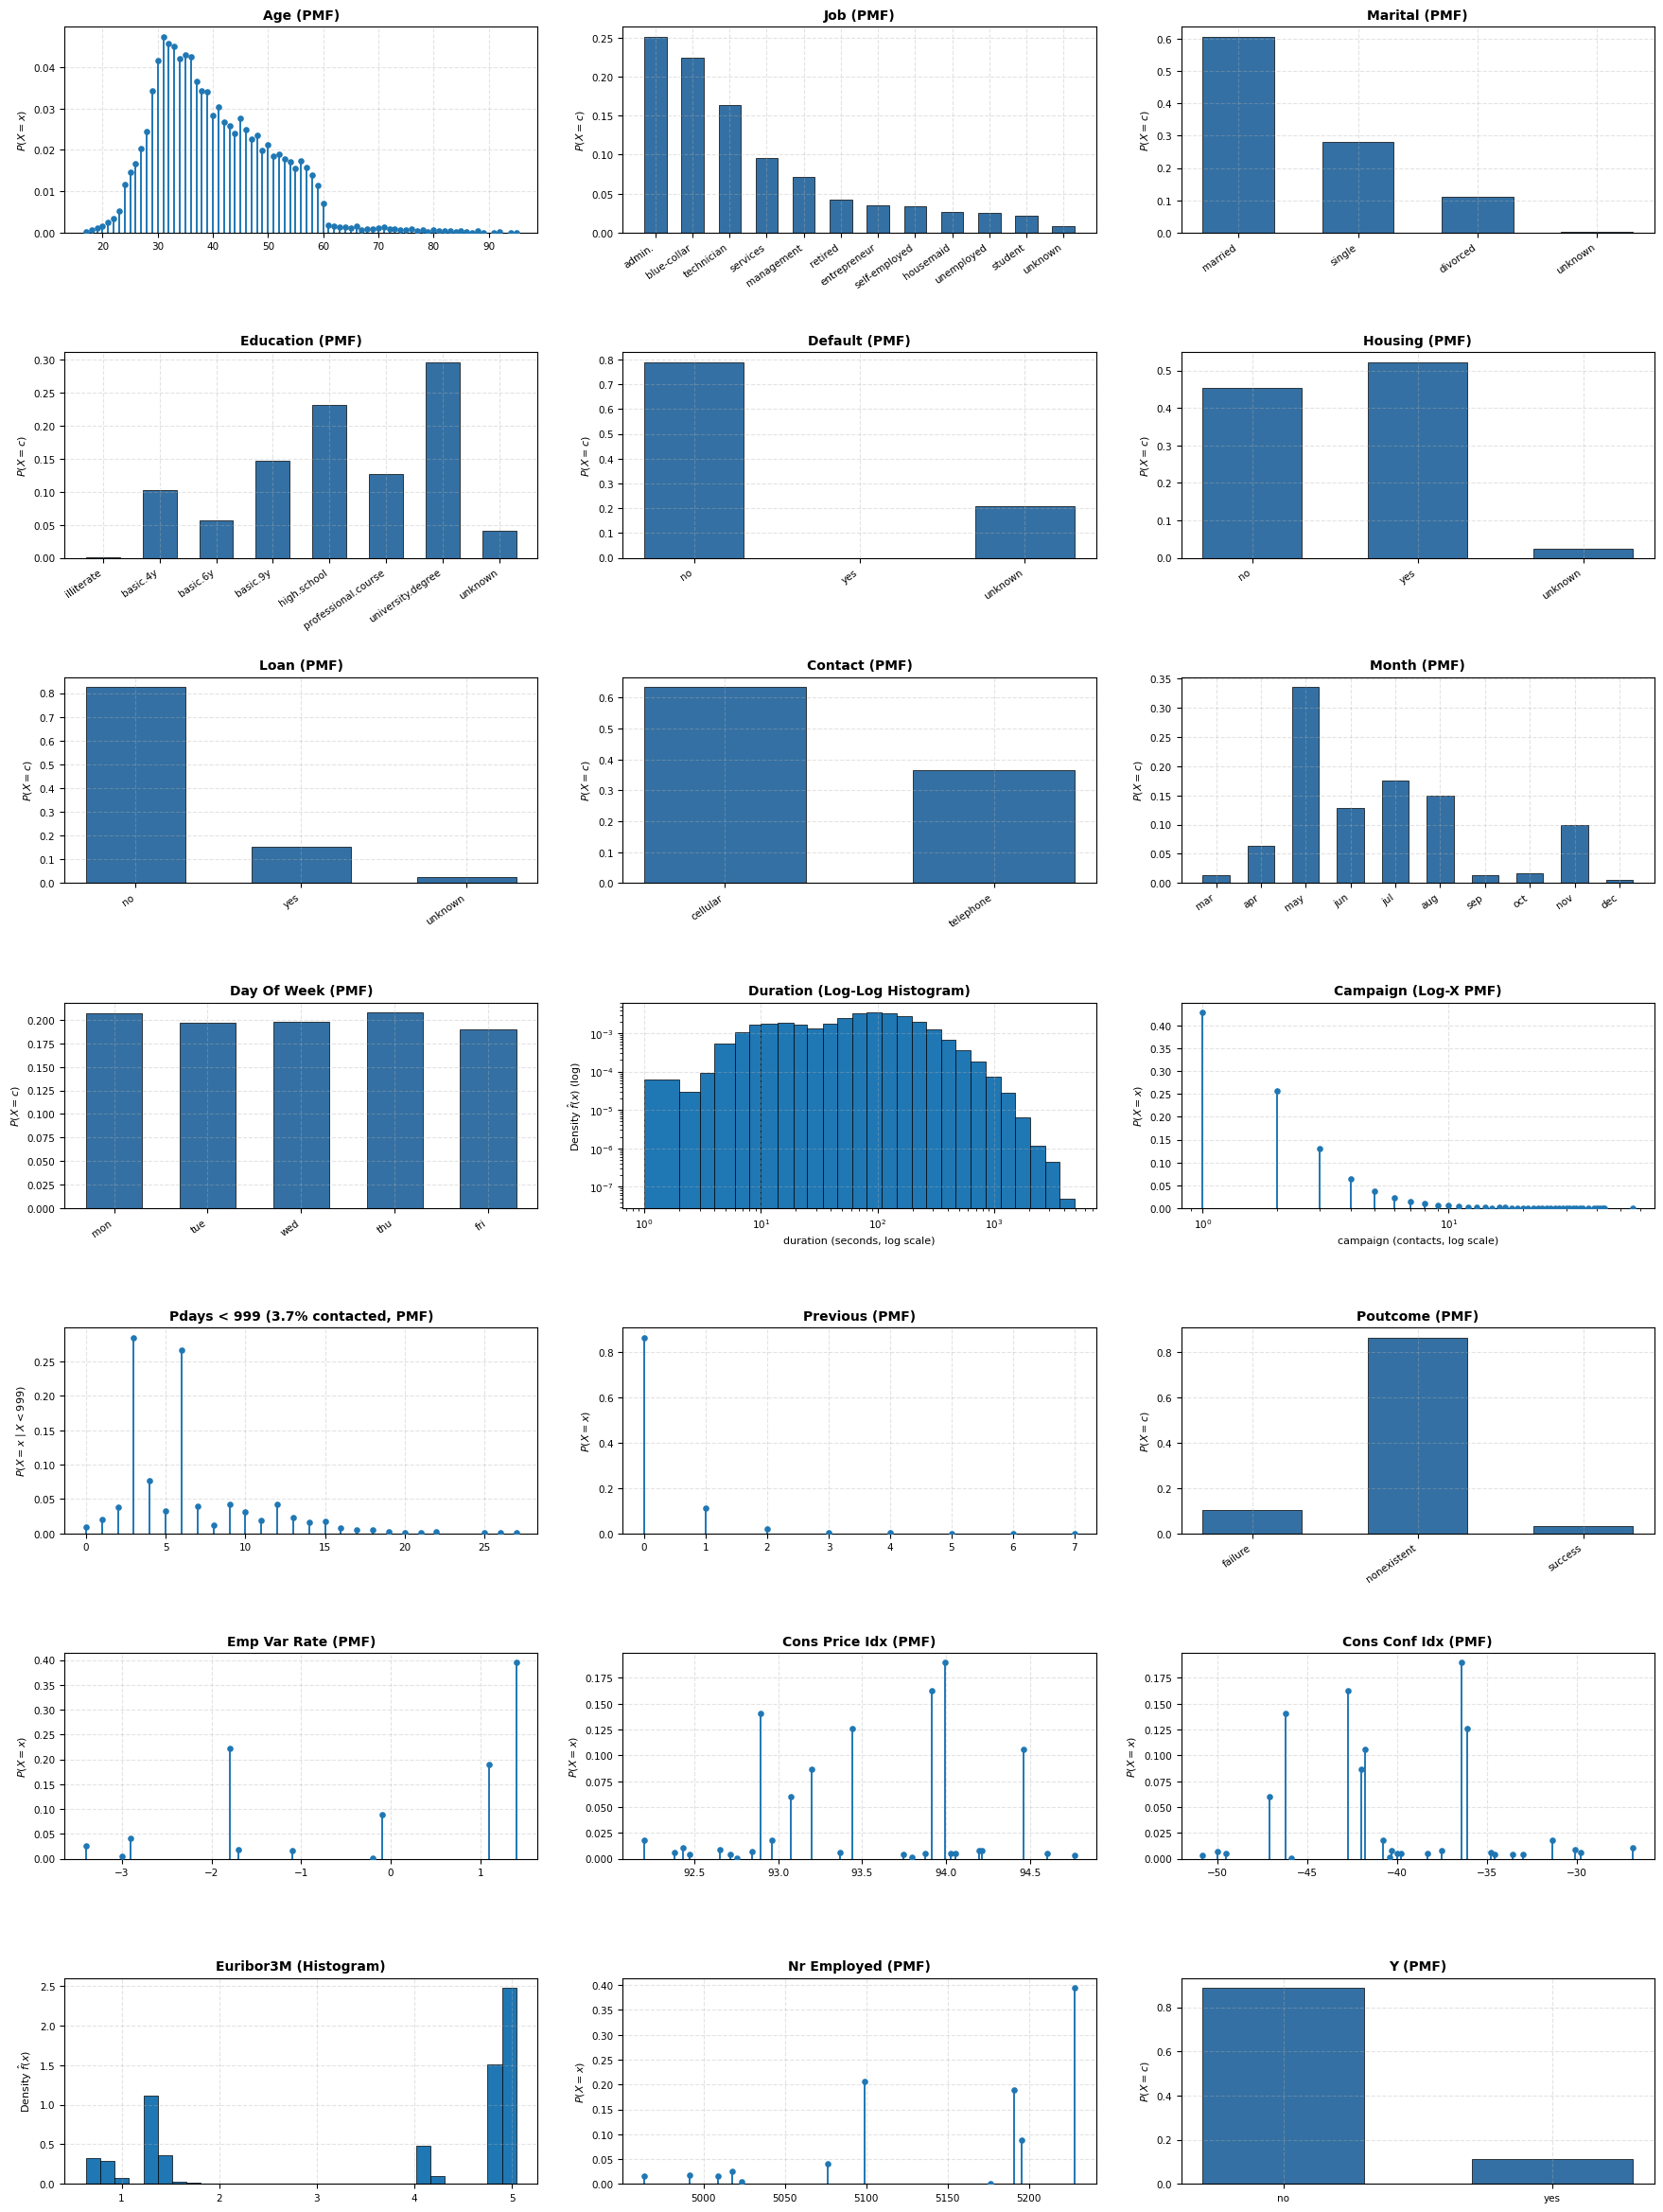

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# 1. Robust Ingestion & Data Hygiene
# -------------------------------------------------------------------------
df = pd.read_csv("ds_train.csv", sep=None, engine="python")

# Handle unseparated single-column data if present
if df.shape[1] == 1 and ";" in str(df.columns[0]):
    raw_col = df.columns[0]
    df = df[raw_col].astype(str).str.split(";", expand=True)
    df.columns = [c.strip().strip('"\'') for c in raw_col.split(";")]

# Standardize column headers
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.strip('"\'')
    .str.lower()
    .str.replace(".", "_", regex=False)
)

# Drop index artifacts that trigger catastrophic bar-plot overplotting
drop_cols = [c for c in df.columns if "unnamed" in c or c == "index"]
if drop_cols:
    df.drop(columns=drop_cols, inplace=True)

# Clean string cells
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip().str.strip('"\'').str.lower()

# -------------------------------------------------------------------------
# 2. Variable Classification & Scale Mappings
# -------------------------------------------------------------------------
CONTINUOUS_HIST = {"duration", "euribor3m"}
NEEDLE_PMF = {
    "age", "campaign", "pdays", "previous",
    "emp_var_rate", "cons_price_idx", "cons_conf_idx", "nr_employed"
}

ORDERED_CATEGORIES = {
    "month": ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
    "day_of_week": ["mon", "tue", "wed", "thu", "fri"],
    "education": [
        "illiterate", "basic.4y", "basic.6y", "basic.9y",
        "high.school", "professional.course", "university.degree", "unknown"
    ],
    "default": ["no", "yes", "unknown"],
    "housing": ["no", "yes", "unknown"],
    "loan": ["no", "yes", "unknown"],
    "contact": ["cellular", "telephone"],
    "poutcome": ["failure", "nonexistent", "success"],
    "y": ["no", "yes"],
}

# -------------------------------------------------------------------------
# 3. Dynamic Subplot Matrix
# -------------------------------------------------------------------------
cols = list(df.columns)
ncols = 3
nrows = int(np.ceil(len(cols) / ncols))

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 3.4 * nrows))
axes = axes.flatten()

for i, col in enumerate(cols):
    ax = axes[i]
    rotate_labels = False

    # Treatment 1: Continuous Distributions (Density Histograms)
    if col in CONTINUOUS_HIST:
        s = pd.to_numeric(df[col], errors="coerce").dropna().values
        
        if col == "duration":
            s_pos = s[s > 0]
            # Snap bin boundaries to distinct integer thresholds to prevent sub-integer empty intervals
            bins = np.unique(np.round(np.geomspace(1, s_pos.max(), 30)).astype(int))
            if bins[-1] < s_pos.max():
                bins = np.append(bins, int(np.ceil(s_pos.max())))

            ax.hist(
                s_pos,
                bins=bins,
                density=True,
                color="#1f77b4",
                edgecolor="black",
                linewidth=0.5,
            )
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_xlabel(f"{col} (seconds, log scale)", fontsize=8)
            ax.set_title(
                "Duration (Log-Log Histogram)", fontsize=10, fontweight="bold"
            )
            ax.set_ylabel(r"Density $\hat{f}(x)$ (log)", fontsize=8)
        else:
            ax.hist(s, bins=30, density=True, color="#1f77b4", edgecolor="black", linewidth=0.5)
            ax.set_title(f"{col.replace('_', ' ').title()} (Histogram)", fontsize=10, fontweight="bold")
            ax.set_ylabel(r"Density $\hat{f}(x)$", fontsize=8)

    # Treatment 2: Discrete Counts & Macro Indices (Needle PMF)
    elif col in NEEDLE_PMF:
        s = pd.to_numeric(df[col], errors="coerce").dropna().values

        if col == "pdays":
            contacted = s[s < 999]
            pct_contacted = (len(contacted) / len(s)) * 100
            x_vals, counts = np.unique(contacted, return_counts=True)
            pmf = counts / len(contacted)

            ax.vlines(x_vals, ymin=0, ymax=pmf, color="#1f77b4", linewidth=1.4)
            ax.scatter(x_vals, pmf, color="#1f77b4", s=14, zorder=3)
            ax.set_title(f"Pdays < 999 ({pct_contacted:.1f}% contacted, PMF)", fontsize=10, fontweight="bold")
            ax.set_ylabel(r"$P(X = x \mid X < 999)$", fontsize=8)

        elif col == "campaign":
            x_vals, counts = np.unique(s[s > 0], return_counts=True)
            pmf = counts / len(s)

            ax.vlines(x_vals, ymin=0, ymax=pmf, color="#1f77b4", linewidth=1.4)
            ax.scatter(x_vals, pmf, color="#1f77b4", s=14, zorder=3)
            ax.set_xscale("log")
            ax.set_xlabel("campaign (contacts, log scale)", fontsize=8)
            ax.set_title("Campaign (Log-X PMF)", fontsize=10, fontweight="bold")
            ax.set_ylabel(r"$P(X = x)$", fontsize=8)

        else:
            x_vals, counts = np.unique(s, return_counts=True)
            pmf = counts / len(s)

            ax.vlines(x_vals, ymin=0, ymax=pmf, color="#1f77b4", linewidth=1.4)
            ax.scatter(x_vals, pmf, color="#1f77b4", s=14, zorder=3)
            ax.set_title(f"{col.replace('_', ' ').title()} (PMF)", fontsize=10, fontweight="bold")
            ax.set_ylabel(r"$P(X = x)$", fontsize=8)

    # Treatment 3: Low-Cardinality Categorical Features (Bar PMF)
    else:
        counts = df[col].value_counts()
        
        # Guard against high-cardinality columns freezing Matplotlib
        if len(counts) > 50:
            counts = counts.head(50)
            ax.text(0.5, 0.5, f"Truncated to top 50 categories\n(Total: {df[col].nunique()})",
                    ha="center", va="center", transform=ax.transAxes, fontsize=8)

        total_obs = len(df[col].dropna())

        if col in ORDERED_CATEGORIES:
            order = [c for c in ORDERED_CATEGORIES[col] if c in counts.index]
            remaining = [c for c in counts.index if c not in order]
            counts = counts.reindex(order + remaining, fill_value=0)
        else:
            counts = counts.sort_values(ascending=False)

        pmf = counts / total_obs
        labels = [str(k) for k in pmf.index]

        ax.bar(labels, pmf.values, width=0.6, color="#3470a3", edgecolor="black", linewidth=0.5)
        ax.set_ylabel(r"$P(X = c)$", fontsize=8)
        ax.set_title(f"{col.replace('_', ' ').title()} (PMF)", fontsize=10, fontweight="bold")
        rotate_labels = len(labels) > 3 or any(len(lbl) > 5 for lbl in labels)

    if not (col in CONTINUOUS_HIST and col == "duration"):
        ax.set_ylim(bottom=0)
    ax.tick_params(axis="both", labelsize=7.5)
    ax.grid(True, linestyle="--", alpha=0.35)

    if rotate_labels:
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

for j in range(len(cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout(pad=2.2)
plt.show()

In [4]:
import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# 1. Count 'yes' in 'default'
# -------------------------------------------------------------------------
default_series = df["default"].astype(str).str.strip().str.lower()
n_default_yes = (default_series == "yes").sum()

print("=" * 65)
print("1. DEFAULT FREQUENCY AUDIT")
print("=" * 65)
print(f"Number of 'yes' in default: {n_default_yes}")
print("\nFull distribution:")
print(default_series.value_counts(dropna=False))

1. DEFAULT FREQUENCY AUDIT
Number of 'yes' in default: 3

Full distribution:
no         26017
unknown     6920
yes            3
Name: default, dtype: int64


## Find outliers

visually no outliers, as dataset is large outliers wouldn't be removed in the first place, no further checks done

## Removing unaccessable data

Duration is unknown before calling, thus it will be removed

In [5]:
import pandas as pd

# Load dataset with delimiter detection
sep = ";" if ";" in open("ds_train.csv", "r", encoding="utf-8").readline() else ","
df_train = pd.read_csv("ds_train.csv", sep=sep)

# Standardize headers to snake_case
df_train.columns = (
    df_train.columns.astype(str)
    .str.strip()
    .str.strip('"\'')
    .str.lower()
    .str.replace(".", "_", regex=False)
)

# Eliminate data leakage feature
if "duration" in df_train.columns:
    df_train.drop(columns=["duration"], inplace=True)

# Persist cleaned dataset
df_train.to_csv("ds_train.csv", index=False)
print(f"'duration' removed. Remaining columns: {df_train.shape[1]}")

'duration' removed. Remaining columns: 1


## Transforming the data

In [13]:
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)


def halve_values(x):
    return x / 2.0


# 1. Robust Load & Delimiter Detection
with open("ds_train.csv", "r", encoding="utf-8") as f:
    first_line = f.readline()
sep = ";" if ";" in first_line else ","

df_train = pd.read_csv("ds_train.csv", sep=sep)

# Split single-column format if delimiter sniffer was bypassed
if df_train.shape[1] == 1 and ";" in str(df_train.columns[0]):
    raw_col = df_train.columns[0]
    df_train = df_train[raw_col].astype(str).str.split(";", expand=True)
    df_train.columns = [c.strip().strip('"\'') for c in raw_col.split(";")]

# Standardize column headers
df_train.columns = (
    df_train.columns.astype(str)
    .str.strip()
    .str.strip('"\'')
    .str.lower()
    .str.replace(".", "_", regex=False)
)

# Strip surrounding whitespace and quotes from all text values
for col in df_train.select_dtypes(include="object").columns:
    df_train[col] = df_train[col].astype(str).str.strip().str.strip('"\'').str.lower()

# Remove duration to prevent data leakage
if "duration" in df_train.columns:
    df_train.drop(columns=["duration"], inplace=True)

# 2. Extract Target (y) and Features (X)
if "y" not in df_train.columns:
    raise KeyError(f"Target 'y' not found. Available columns: {list(df_train.columns)}")

# Convert target to binary integer
y_train = df_train["y"].map({"no": 0, "yes": 1, 0: 0, 1: 1, "0": 0, "1": 1}).astype(int)
X_train = df_train.drop(columns=["y"])

# 3. Categorize Feature Subsets
ordinal_candidates = ["education"]
education_order = [[
    "illiterate", "basic.4y", "basic.6y", "basic.9y",
    "high.school", "professional.course", "university.degree", "unknown"
]]

# Variables with {'no', 'unknown', 'yes'} mapping: no -> 0, unknown -> 0.5, yes -> 1
ternary_candidates = ["default", "housing", "loan"]

# Pure binary features: telephone -> 0, cellular -> 1
binary_candidates = ["contact"]
contact_order = [["telephone", "cellular"]]

# Remaining nominal features with > 2 categories
nominal_candidates = [
    "job", "marital", "month", "day_of_week", "poutcome"
]

numeric_candidates = [
    "age", "campaign", "pdays", "previous", "emp_var_rate",
    "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed"
]

# Keep only features present in X_train
ordinal_features = [c for c in ordinal_candidates if c in X_train.columns]
ternary_features = [c for c in ternary_candidates if c in X_train.columns]
ternary_order = [["no", "unknown", "yes"]] * len(ternary_features)
binary_features = [c for c in binary_candidates if c in X_train.columns]
nominal_features = [c for c in nominal_candidates if c in X_train.columns]
numeric_features = [c for c in numeric_candidates if c in X_train.columns]

# Ensure numeric features are properly cast
for col in numeric_features:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")

# 4. Construct Scikit-Learn Preprocessing Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "ord",
            OrdinalEncoder(categories=education_order, handle_unknown="use_encoded_value", unknown_value=-1),
            ordinal_features
        ),
        (
            "ternary",
            Pipeline([
                (
                    "encoder",
                    OrdinalEncoder(categories=ternary_order, handle_unknown="use_encoded_value", unknown_value=-1)
                ),
                (
                    "scaler",
                    FunctionTransformer(halve_values, feature_names_out="one-to-one")
                ),
            ]),
            ternary_features
        ),
        (
            "bin",
            OrdinalEncoder(categories=contact_order, handle_unknown="use_encoded_value", unknown_value=-1),
            binary_features
        ),
        (
            "nom",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            nominal_features
        ),
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
    ],
    verbose_feature_names_out=False
)

# 5. Fit Transformer Strictly on Training Data
X_train_transformed = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()

# 6. Reassemble Full DataFrame (Features + Target y)
ds_train_transformed = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)
ds_train_transformed["y"] = y_train.values

# 7. Persist Pipeline and Dataset
joblib.dump(preprocessor, "fitted_preprocessor.joblib")
ds_train_transformed.to_csv("ds_train_transformed.csv", index=False)

print(f"Transformed training set shape: {ds_train_transformed.shape}")
print("Target 'y' retained. Binary and ternary features mapped to single columns.")

Transformed training set shape: (32940, 49)
Target 'y' retained. Binary and ternary features mapped to single columns.


## Reducing dimensionality

Gemini reasoning

1. Statistical RationalesNear-Zero Variance Screening (NZV)In one-hot encoded spaces, dummy levels with extreme class imbalances (e.g., $p_j < 0.005$) yield a Bernoulli variance of $\text{Var}(X_j) = p_j(1 - p_j) < 0.005$. These quasi-constant columns contribute negligible entropy to decision trees, introduce singular sub-spaces, and cause zero-distance metric collapse in $k$-NN algorithms. Screening for near-zero variance removes these degenerate dimensions before computing more computationally intensive dependency metrics.Feature-to-Target Mutual Information ($I(X; Y)$)Mutual Information measures the reduction in uncertainty (Shannon entropy) of the subscription target $y$ given predictor $X_j$:$$I(X_j; Y) = H(Y) - H(Y \mid X_j) = \sum_{y \in \{0, 1\}} \int p(x_j, y) \log \left(\frac{p(x_j, y)}{p(x_j)p(y)}\right) dx_j$$Unlike linear correlation coefficients or ANOVA $F$-tests, $I(X_j; Y)$ requires no distributional assumptions, handles multimodal densities (such as euribor3m), and detects non-linear decision boundaries. It serves as the primary filter for ranking feature relevance.Pairwise Mutual Information & Variance Inflation Factor (VIF)While feature-to-target MI ranks individual predictive power, it does not detect redundancy among predictors. Pairwise Mutual Information identifies non-linear bivariate collinearity between feature pairs. The Variance Inflation Factor complements this by detecting higher-order linear combinations across multiple variables:$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$where $R_j^2$ is the coefficient of determination obtained from regressing $X_j$ onto all remaining features. Diagnosing this system-level redundancy is necessary to prevent conditional independence violations in Naive Bayes and unstable margin estimation in SVMs.

=== Step 1: Near-Zero Variance Screening (Var <= 0.005) ===
Initial feature count:    48
Features flagged/dropped: 2
  [-] marital_unknown                (Var = 0.00194)
  [-] month_dec                      (Var = 0.00465)
Features remaining:       46

=== Step 2: Feature-to-Target Relevance Filtering (MI <= 0.005) ===
Features evaluated:       46
Features dropped (MI low):30
  [-] job_housemaid                  (MI = 0.00000 nats)
  [-] poutcome_failure               (MI = 0.00000 nats)
  [-] day_of_week_thu                (MI = 0.00000 nats)
  [-] month_jun                      (MI = 0.00000 nats)
  [-] job_entrepreneur               (MI = 0.00000 nats)
  [-] job_management                 (MI = 0.00028 nats)
  [-] month_aug                      (MI = 0.00042 nats)
  [-] job_student                    (MI = 0.00050 nats)
  [-] loan                           (MI = 0.00085 nats)
  [-] job_retired                    (MI = 0.00114 nats)
  [-] marital_single                 (MI = 0.00132 

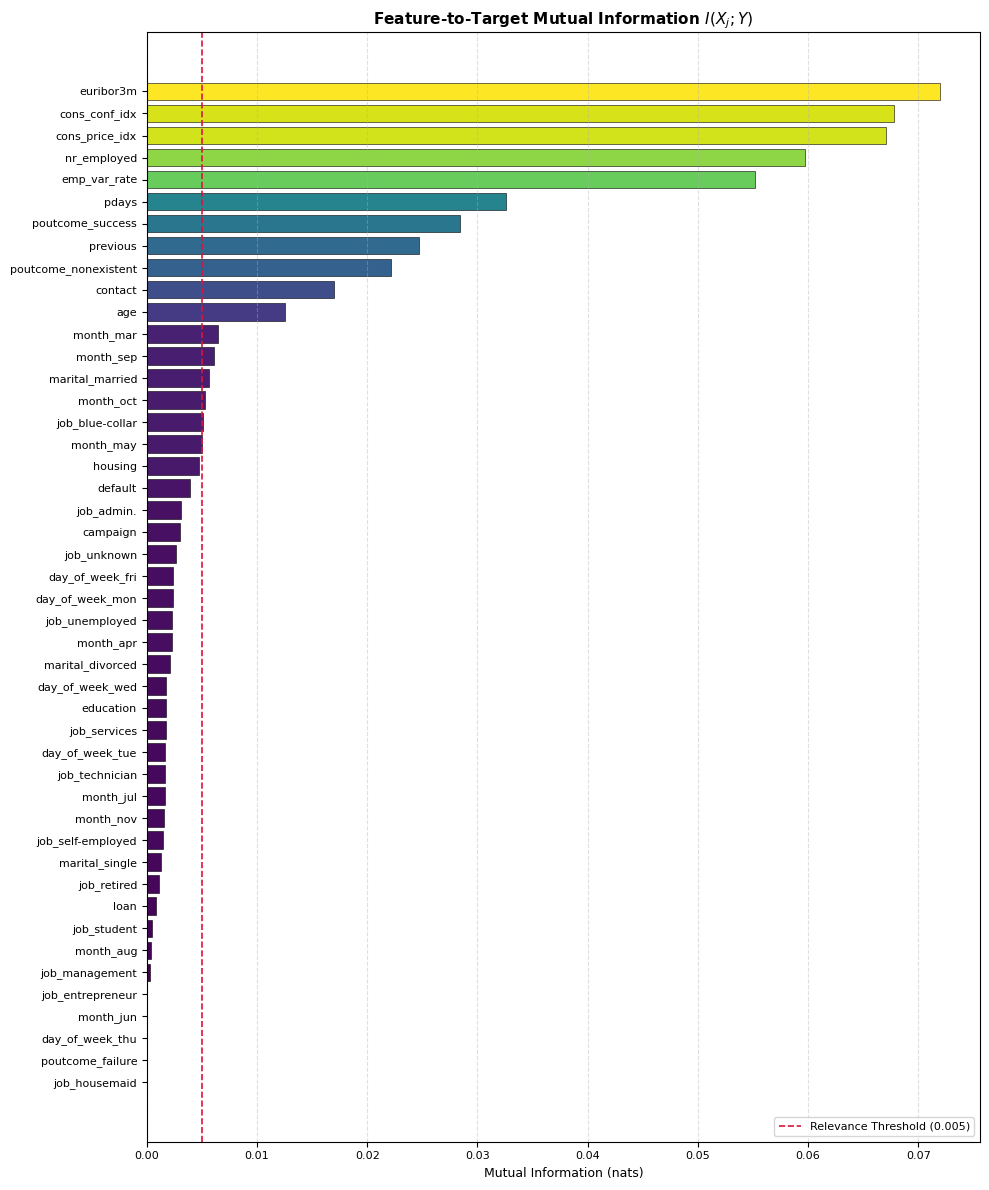

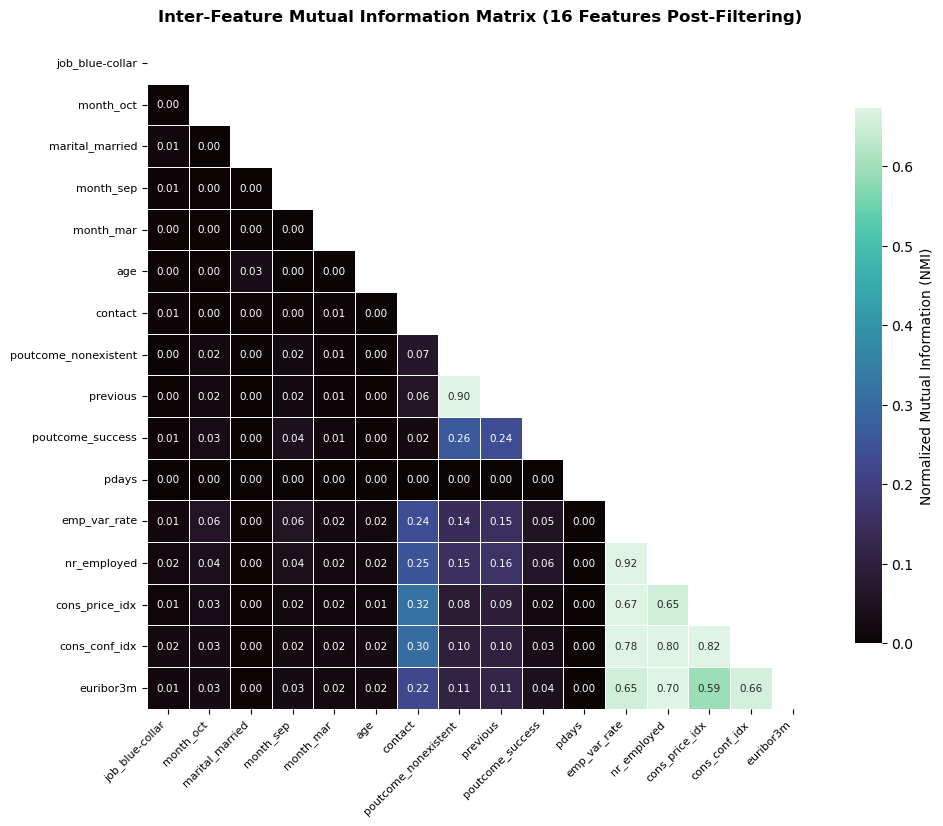

=== Step 3: Multicollinearity Diagnostics (VIF) ===
Feature                          VIF  Status
--------------------------------------------------
euribor3m                      64.03  Severe Multicollinearity (> 10)
emp_var_rate                   32.94  Severe Multicollinearity (> 10)
nr_employed                    31.46  Severe Multicollinearity (> 10)
cons_price_idx                  6.32  Acceptable
cons_conf_idx                   2.66  Acceptable
previous                        1.80  Acceptable
pdays                           1.62  Acceptable
age                             1.02  Acceptable


In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.metrics import normalized_mutual_info_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

# -------------------------------------------------------------------------
# 0. Load Transformed Dataset
# -------------------------------------------------------------------------
df = pd.read_csv("ds_train_transformed.csv")
X = df.drop(columns=["y"])
y = df["y"].astype(int)

# -------------------------------------------------------------------------
# Step 1: Near-Zero Variance Screening
# -------------------------------------------------------------------------
var_threshold = 0.005
selector = VarianceThreshold(threshold=var_threshold)
selector.fit(X)

variances = pd.Series(selector.variances_, index=X.columns)
dropped_nzv = variances[variances <= var_threshold].index.tolist()
retained_after_nzv = variances[variances > var_threshold].index.tolist()

print("\033[1m=== Step 1: Near-Zero Variance Screening (Var <= 0.005) ===\033[0m")
print(f"Initial feature count:    {X.shape[1]}")
print(f"Features flagged/dropped: {len(dropped_nzv)}")
for col in dropped_nzv:
    print(f"  [-] {col:<30} (Var = {variances[col]:.5f})")
print(f"Features remaining:       {len(retained_after_nzv)}\n")

X_step1 = X[retained_after_nzv]

# -------------------------------------------------------------------------
# Step 2: Feature-to-Target Mutual Information I(X; Y)
# -------------------------------------------------------------------------
mi_threshold = 0.005
mi_scores = mutual_info_classif(X_step1, y, discrete_features="auto", random_state=42)
mi_series = pd.Series(mi_scores, index=X_step1.columns).sort_values(ascending=True)

dropped_mi = mi_series[mi_series <= mi_threshold].index.tolist()
selected_features = mi_series[mi_series > mi_threshold].index.tolist()

print("\033[1m=== Step 2: Feature-to-Target Relevance Filtering (MI <= 0.005) ===\033[0m")
print(f"Features evaluated:       {len(mi_series)}")
print(f"Features dropped (MI low):{len(dropped_mi)}")
for col in dropped_mi:
    print(f"  [-] {col:<30} (MI = {mi_series[col]:.5f} nats)")
print(f"Features selected:        {len(selected_features)}\n")

# Graphic 1: Colored Horizontal Bar Chart for all Step 1 Features
fig_h = max(6, int(len(mi_series) * 0.28))
plt.figure(figsize=(10, fig_h))
norm = plt.Normalize(mi_series.min(), mi_series.max())
colors = plt.cm.viridis(norm(mi_series.values))

plt.barh(mi_series.index, mi_series.values, color=colors, edgecolor="black", linewidth=0.4)
plt.axvline(
    x=mi_threshold,
    color="crimson",
    linestyle="--",
    linewidth=1.2,
    label=f"Relevance Threshold ({mi_threshold})",
)
plt.title(r"Feature-to-Target Mutual Information $I(X_j; Y)$", fontsize=11, fontweight="bold")
plt.xlabel("Mutual Information (nats)", fontsize=9)
plt.tick_params(axis="both", labelsize=8)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

# Retain only relevant features for matrix and VIF analyses
X_selected = X_step1[selected_features]

# -------------------------------------------------------------------------
# Step 3A: Full Inter-Feature Dependency Matrix (All Surviving Features)
# -------------------------------------------------------------------------
# Discretize continuous columns to enable fast, robust Shannon mutual information
X_discrete = X_selected.copy()
for col in X_discrete.columns:
    if X_discrete[col].nunique() > 10:
        X_discrete[col] = pd.qcut(X_discrete[col], q=10, labels=False, duplicates="drop")
    else:
        X_discrete[col] = pd.factorize(X_discrete[col])[0]

n_feats = X_discrete.shape[1]
feat_names = X_discrete.columns
mi_mat = np.zeros((n_feats, n_feats))

for i in range(n_feats):
    for j in range(i, n_feats):
        if i == j:
            val = 1.0
        else:
            val = normalized_mutual_info_score(X_discrete.iloc[:, i], X_discrete.iloc[:, j])
        mi_mat[i, j] = val
        mi_mat[j, i] = val

dep_matrix = pd.DataFrame(mi_mat, index=feat_names, columns=feat_names)
mask = np.triu(np.ones_like(dep_matrix, dtype=bool))

# Dynamic color scale clipping via 95th percentile to prevent skew from extreme values (e.g., 1.0)
off_diag_vals = dep_matrix.values[np.tril_indices_from(dep_matrix, k=-1)]
vmax_val = float(np.clip(np.percentile(off_diag_vals, 95), 0.25, 1.0)) if len(off_diag_vals) > 0 else 1.0

matrix_dim = max(10, int(len(selected_features) * 0.65))
plt.figure(figsize=(matrix_dim, matrix_dim * 0.85))

sns.heatmap(
    dep_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="mako",
    vmin=0,
    vmax=vmax_val,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": r"Normalized Mutual Information (NMI)", "shrink": 0.75},
    annot_kws={"size": 7.5},
)
plt.title(
    f"Inter-Feature Mutual Information Matrix ({len(selected_features)} Features Post-Filtering)",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.xticks(fontsize=8, rotation=45, ha="right")
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Step 3B: Multicollinearity Diagnostics (VIF)
# -------------------------------------------------------------------------
continuous_candidates = [
    "euribor3m",
    "cons_conf_idx",
    "cons_price_idx",
    "nr_employed",
    "emp_var_rate",
    "pdays",
    "previous",
    "age",
    "campaign",
]
continuous_selected = [c for c in continuous_candidates if c in selected_features]

vif_data = pd.DataFrame({"Feature": continuous_selected})
vif_data["VIF"] = [
    variance_inflation_factor(X_selected[continuous_selected].values, i)
    for i in range(len(continuous_selected))
]
vif_data = vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)

print("\033[1m=== Step 3: Multicollinearity Diagnostics (VIF) ===\033[0m")
print(f"{'Feature':<25} {'VIF':>10}  {'Status'}")
print("-" * 50)
for _, row in vif_data.iterrows():
    val = row["VIF"]
    status = "\033[91mSevere Multicollinearity (> 10)\033[0m" if val > 10 else "\033[92mAcceptable\033[0m"
    print(f"{row['Feature']:<25} {val:>10.2f}  {status}")

## Generate trimmed datasets with fewer variables
#### Feature Subset Selection Rationale

Three distinct feature subsets were constructed to align with the varying mathematical assumptions of Random Forest, Support Vector Machines, Naive Bayes, and K-Nearest Neighbors:

* **Set 1: High-Capacity Ensemble Set (14 Features + Target)**
  Curated for tree ensembles (**Random Forest**). Tree architectures isolate orthogonal decision boundaries via recursive splitting and remain invariant to linear multicollinearity. This set maximizes information retention by keeping all macroeconomic indicators alongside high-yield calendar anomalies (`month_mar`, `month_sep`, `month_oct`) and demographic variables that cleared the $I(X_j; Y) > 0.005$ threshold. `poutcome_nonexistent` was excluded due to its deterministic coupling with `previous` ($\text{NMI} = 0.90$), and `job_blue-collar` was omitted as an isolated category fragment sitting on the empirical noise floor ($I = 0.0051$).

* **Set 2: Collinearity-Resolved Core Set (7 Features + Target)**
  Engineered for maximum-margin planes (**SVM with RBF Kernel**) and probabilistic models (**Gaussian Naive Bayes**). The macroeconomic block suffers from extreme variance inflation ($\text{VIF} > 30$ for `emp_var_rate` and `nr_employed`), violating the class-conditional independence assumption $\prod_{j=1}^p P(x_j \mid y)$ in Naive Bayes and skewing gradient updates in regularized hyperplanes. We retain only `euribor3m` ($I = 0.072$) as the dominant economic driver and `cons_conf_idx` ($\text{VIF} = 2.66$) as an orthogonal consumer sentiment proxy. Fragmented calendar dummies (`month_*`) and borderline demographic indicators were eliminated to prevent uninterpretable composite reference states, bounding all remaining predictors to $\text{VIF} < 3.0$.

* **Set 3: Minimalist Orthogonal Set (5 Features + Target)**
  Formulated specifically for metric-based learning (**KNN**) to mitigate the curse of dimensionality. As dimension $p$ increases, volume in Euclidean space grows exponentially, causing pairwise distances to converge toward uniformity ($\lim_{p \to \infty} \frac{\text{dist}_{\max} - \text{dist}_{\min}}{\text{dist}_{\min}} \to 0$) and degrading neighborhood locality. This minimal set retains exactly one orthogonal signal per domain axis: macroeconomic climate (`euribor3m`), historical contact decay (`pdays`), prior conversion polarity (`poutcome_success`), infrastructure access channel (`contact`), and client lifecycle stage (`age`).

In [16]:
import os
import pandas as pd

# -------------------------------------------------------------------------
# 1. Define Curated Feature Sets
# -------------------------------------------------------------------------
feature_subsets = {
    "set1_high_capacity": [
        "euribor3m",
        "cons_conf_idx",
        "cons_price_idx",
        "nr_employed",
        "emp_var_rate",
        "pdays",
        "poutcome_success",
        "previous",
        "contact",
        "age",
        "month_mar",
        "month_sep",
        "month_oct",
        "marital_married",
    ],
    "set2_core_decorrelated": [
        "euribor3m",
        "cons_conf_idx",
        "pdays",
        "poutcome_success",
        "previous",
        "contact",
        "age",
    ],
    "set3_minimalist_knn": [
        "euribor3m",
        "pdays",
        "poutcome_success",
        "contact",
        "age",
    ],
}

# -------------------------------------------------------------------------
# 2. Load Transformed Data
# -------------------------------------------------------------------------
train_path = "ds_train_transformed.csv"
test_path = "ds_test_transformed.csv"

if not os.path.exists(train_path):
    raise FileNotFoundError(f"Source file '{train_path}' not found.")

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path) if os.path.exists(test_path) else None

# -------------------------------------------------------------------------
# 3. Export Global Subsets
# -------------------------------------------------------------------------
print("Generating curated datasets...")

for set_name, features in feature_subsets.items():
    cols_to_extract = features + ["y"]

    # Verify column existence in training set
    missing_cols = [c for c in cols_to_extract if c not in df_train.columns]
    if missing_cols:
        raise KeyError(
            f"Columns {missing_cols} not present in '{train_path}'."
        )

    # Slice and persist training split
    train_subset = df_train[cols_to_extract]
    train_output_filename = f"ds_train_{set_name}.csv"
    train_subset.to_csv(train_output_filename, index=False)

    print(
        f"Saved: {train_output_filename:<32} | Dimensions: {train_subset.shape}"
    )

    # Slice and persist test split if available
    if df_test is not None:
        test_subset = df_test[cols_to_extract]
        test_output_filename = f"ds_test_{set_name}.csv"
        test_subset.to_csv(test_output_filename, index=False)
        print(
            f"Saved: {test_output_filename:<32} | Dimensions: {test_subset.shape}"
        )

print("\nDataset generation complete.")

Generating curated datasets...
Saved: ds_train_set1_high_capacity.csv  | Dimensions: (32940, 15)
Saved: ds_train_set2_core_decorrelated.csv | Dimensions: (32940, 8)
Saved: ds_train_set3_minimalist_knn.csv | Dimensions: (32940, 6)

Dataset generation complete.
